# Porównanie metod na mini zbiorze (spam w klasie pozytywnej)

Wszystkie modele wariantu `spam_1` oceniane na tych samych 2305 wiadomościach mini zbioru (`mini_test_set.ipynb`): 1500 z testu
ID podziału 42 i 805 z OOD.

- **Modele uczone (klasyczne i BERT):** wyniki pochodzą z plików `predictions.csv` zapisanych przez ich notatniki. Mini zbiór
  jest podzbiorem testu ID i korpusu OOD, więc niczego nie uczono ponownie. Próg to próg danego modelu dobrany na val przy
  ważonym FPR 1%.
- **LLM:** wyniki z `llm_zero_shot_spam_1` i `llm_few_shot_spam_1`, próg 0.5.
- **Ograniczenia:** zbiór jest zbalansowany, więc precision i AUCPR nie są porównywalne z pełnym testem. Progi modeli uczonych
  i LLM mają inne źródło, dlatego decyzyjne metryki (recall, FPR) porównuje się ostrożnie, a głównym kryterium jest ROC AUC.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import ID_SOURCES, INK_SECONDARY, OOD_SOURCES, compute_metrics, corpus_metrics

EXPERIMENT = "mini_test_comparison_spam_1"
LABEL = "label_spam_1"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 200, "display.float_format", "{:.4f}".format)

SUPERVISED = {
    "BoW + LR": ("klasyczne", "bow_lr_spam_1"), "TF-IDF + XGB": ("klasyczne", "tf_idf_xgb_spam_1"),
    "TF-IDF + MLP": ("klasyczne", "tf_idf_mlp_spam_1"), "fastText + XGB": ("klasyczne", "fasttext_xgb_spam_1"),
    "fastText + MLP": ("klasyczne", "fasttext_mlp_spam_1"), "BERT 512": ("BERT", "bert_512_spam_1"),
    "BELT": ("BERT", "bert_belt_spam_1"),
}
LLM_MODELS = ["qwen2.5:7b", "qwen3.5:9b", "gemma4:12b", "gpt-oss:20b"]
LLM_MODES = {"zero-shot": "llm_zero_shot_spam_1", "few-shot": "llm_few_shot_spam_1"}
LLM_THRESHOLD = 0.5
FAMILY_COLORS = {"klasyczne": "#2a78d6", "BERT": "#1baf7a", "LLM": "#eb6834"}

mini = pd.read_parquet(ROOT / "data" / "mini_test.parquet")
print(mini.groupby("korpus").size().to_dict())

{'ID': 1500, 'OOD': 805}


## Wyniki modeli na mini zbiorze

Każdy model musi mieć wynik dla wszystkich wiadomości mini zbioru. Dla modeli uczonych sprawdza się też, że zapisana decyzja
zgadza się z progiem z `threshold.csv`.

In [2]:
def attach(predictions):
    frame = mini.merge(predictions[["id", "score"]], on="id", how="left", validate="one_to_one")
    assert frame.score.notna().all(), "brak wyników dla części mini zbioru"
    return frame


runs = {}  # model: (rodzina, próg, ramka)
for name, (family, experiment) in SUPERVISED.items():
    tables = ROOT / "results" / experiment / "tables"
    predictions = pd.read_csv(tables / "predictions.csv", dtype={"id": str})
    threshold = float(pd.read_csv(tables / "threshold.csv")["próg"].iloc[0])
    assert ((predictions.score >= threshold).astype(int) == predictions.pred).all()
    runs[name] = (family, threshold, attach(predictions))
for mode, experiment in LLM_MODES.items():
    for model in LLM_MODELS:
        path = ROOT / "results" / experiment / "tables" / f"predictions_{model.replace(':', '_')}.csv"
        runs[f"{model} {mode}"] = ("LLM", LLM_THRESHOLD, attach(pd.read_csv(path, dtype={"id": str})))
print(len(runs), "modeli")

15 modeli


## Metryki dla ID i OOD

`próg` to próg decyzji danego modelu. Macierze pomyłek wszystkich modeli są w jednej tabeli `confusion_matrices.csv`.

In [3]:
metric_tables, source_tables, matrix_rows = [], [], []
for name, (family, threshold, frame) in runs.items():
    corpus_sets = {korpus: (part[LABEL], part.score.to_numpy()) for korpus, part in frame.groupby("korpus")}
    metric_tables.append(corpus_metrics(corpus_sets, threshold).assign(model=name, rodzina=family, próg=threshold))
    source_sets = {
        source: (frame.loc[frame.source == source, LABEL], frame.loc[frame.source == source, "score"].to_numpy())
        for source in ID_SOURCES + OOD_SOURCES
    }
    source_tables.append(corpus_metrics(source_sets, threshold).assign(model=name, rodzina=family))
    for korpus, (labels, scores) in corpus_sets.items():
        result = compute_metrics(labels, scores, threshold)
        matrix_rows.append({"model": name, "korpus": korpus, **{key: int(result[key]) for key in ("tn", "fp", "fn", "tp")}})

metrics = pd.concat(metric_tables).rename_axis("korpus").reset_index().set_index(["model", "korpus"])
metrics.to_csv(TABLES / "metrics.csv")
metrics_by_source = pd.concat(source_tables).rename_axis("source").reset_index().set_index(["model", "source"])
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv")
pd.DataFrame(matrix_rows).to_csv(TABLES / "confusion_matrices.csv", index=False)
display(metrics.drop(columns="rodzina").unstack("korpus")[["roc_auc", "recall", "fpr", "f1"]])

roc_auc        recall           fpr            f1       
korpus                     ID    OOD     ID    OOD     ID    OOD     ID    OOD
model                                                                         
BELT                   0.9978 0.7619 0.9733 0.6580 0.0200 0.2808 0.9822 0.6889
BERT 512               0.9985 0.7394 0.9829 0.6392 0.0178 0.3123 0.9876 0.6658
BoW + LR               0.9828 0.8629 0.7810 0.6533 0.0133 0.0814 0.8742 0.7568
TF-IDF + MLP           0.9967 0.8599 0.9248 0.7995 0.0089 0.2205 0.9590 0.8005
TF-IDF + XGB           0.9949 0.8470 0.9133 0.7854 0.0133 0.2651 0.9519 0.7762
fastText + MLP         0.9925 0.7735 0.9200 0.4363 0.0156 0.0787 0.9550 0.5790
fastText + XGB         0.9917 0.7496 0.9057 0.4292 0.0200 0.1417 0.9463 0.5515
gemma4:12b few-shot    0.9867 0.9715 0.9619 0.9670 0.0778 0.1995 0.9642 0.9011
gemma4:12b zero-shot   0.9861 0.9565 0.9800 0.9882 0.1356 0.4304 0.9617 0.8322
gpt-oss:20b few-shot   0.9232 0.8671 0.9476 0.7995 0.1489 0.0892 0.9422 0.8507
gpt-oss:20b zero-shot  0.9220 0.8398 0.9790 0.8750 0.1867 0.1890 0.9510 0.8558
qwen2.5:7b few-shot    0.9700 0.8374 0.9571 0.5920 0.1467 0.0866 0.9477 0.7090
qwen2.5:7b zero-shot   0.9723 0.8867 0.9657 0.7500 0.1533 0.1234 0.9508 0.8061
qwen3.5:9b few-shot    0.9793 0.9416 0.9524 0.9292 0.1022 0.3018 0.9542 0.8446
qwen3.5:9b zero-shot   0.9735 0.9342 0.9381 0.9670 0.1156 0.5617 0.9439 0.7824

## ROC AUC według źródła

ROC AUC nie zależy od progu, więc to główne porównanie. Nazario i Nigerian zawierają tylko phishing, więc nie mają ROC AUC.

In [4]:
overall = metrics.roc_auc.unstack("korpus")[["ID", "OOD"]]
by_source = metrics_by_source.roc_auc.unstack("source")[["trec05", "trec06", "trec07", "ferb", "kd10000", "nebulon", "zeroday"]]
roc_auc_table = overall.join(by_source).loc[list(runs)]
roc_auc_table.insert(0, "rodzina", [runs[name][0] for name in roc_auc_table.index])
roc_auc_table.to_csv(TABLES / "roc_auc_by_source.csv")
display(roc_auc_table)

,rodzina,ID,OOD,trec05,trec06,trec07,ferb,kd10000,nebulon,zeroday
model,,,,,,,,,,
BoW + LR,klasyczne,0.9828,0.8629,0.9746,0.9796,0.9853,0.8200,1.0000,0.8032,0.9623
TF-IDF + XGB,klasyczne,0.9949,0.8470,0.9900,0.9960,0.9954,0.8782,1.0000,0.7857,0.9164
TF-IDF + MLP,klasyczne,0.9967,0.8599,0.9948,0.9931,0.9978,0.8373,0.9782,0.8059,0.9232
fastText + XGB,klasyczne,0.9917,0.7496,0.9844,0.9922,0.9933,0.7306,1.0000,0.7626,0.8491
fastText + MLP,klasyczne,0.9925,0.7735,0.9872,0.9928,0.9959,0.7036,1.0000,0.7874,0.8930
BERT 512,BERT,0.9985,0.7394,0.9986,0.9985,0.9992,0.5535,1.0000,0.7737,0.8814
BELT,BERT,0.9978,0.7619,0.9983,0.9971,0.9986,0.6139,1.0000,0.7654,0.8916
qwen2.5:7b zero-shot,LLM,0.9723,0.8867,0.9465,0.9737,0.9834,0.7422,1.0000,0.8707,0.9886
qwen3.5:9b zero-shot,LLM,0.9735,0.9342,0.9376,0.9763,0.9860,0.9150,1.0000,0.8717,0.9959


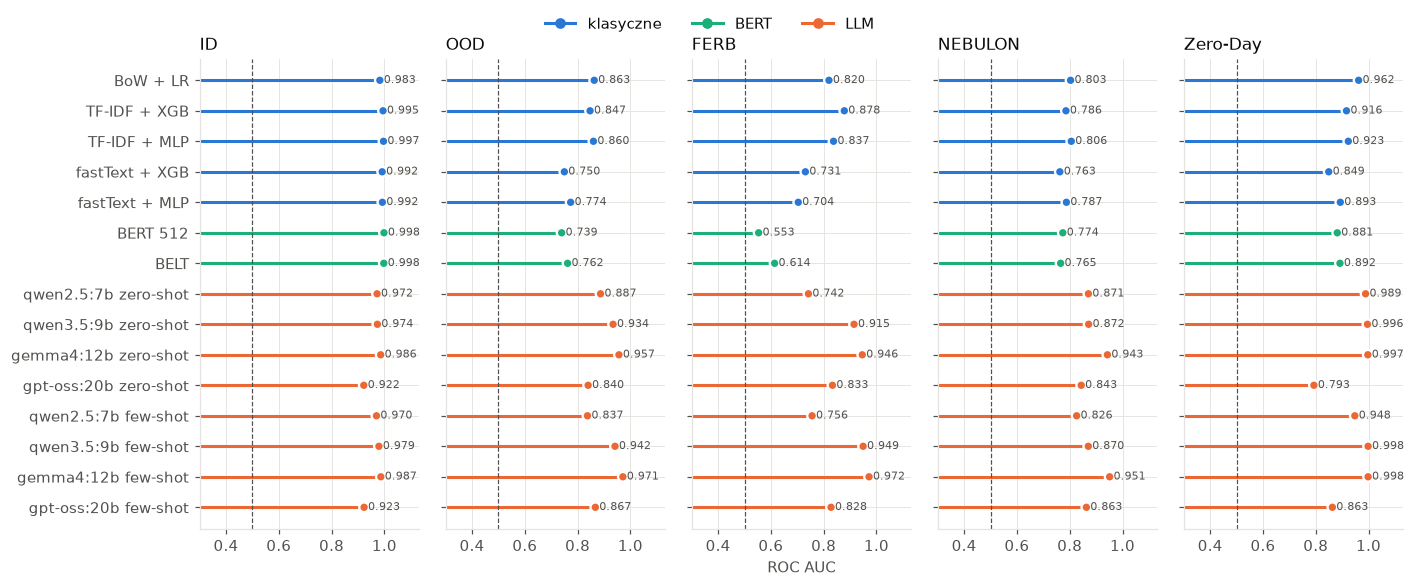

In [5]:
PANELS = {"ID": "ID", "OOD": "OOD", "ferb": "FERB", "nebulon": "NEBULON", "zeroday": "Zero-Day"}
names = list(runs)[::-1]
positions = np.arange(len(names))
figure, axes = plt.subplots(1, len(PANELS), figsize=(13, 5.2), sharey=True)
for axis, (column, title) in zip(axes, PANELS.items()):
    values = roc_auc_table.loc[names, column]
    colors = [FAMILY_COLORS[runs[name][0]] for name in names]
    axis.hlines(positions, 0, values, color=colors, linewidth=2)
    axis.scatter(values, positions, color=colors, s=40, edgecolors="white", linewidths=1.5, zorder=3)
    for position, value in zip(positions, values):
        axis.text(value + 0.015, position, f"{value:.3f}", ha="left", va="center", fontsize=7, color=INK_SECONDARY)
    axis.set(xlim=(0.3, 1.13), xticks=[0.4, 0.6, 0.8, 1.0])
    axis.set_title(title, loc="left")
    axis.axvline(0.5, color=INK_SECONDARY, linewidth=0.8, linestyle="--")
axes[0].set_yticks(positions, names)
axes[len(PANELS) // 2].set_xlabel("ROC AUC")
handles = [plt.Line2D([], [], color=color, marker="o", linewidth=2, label=family) for family, color in FAMILY_COLORS.items()]
figure.legend(handles=handles, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.03))
figure.tight_layout()
figure.savefig(FIGURES / "roc_auc_by_source.pdf", bbox_inches="tight")
plt.show()

## Punkt pracy na OOD

Recall i FPR na OOD przy progu każdego modelu. Modele uczone mają próg dobrany na val ID, więc pokazuje to, jak próg z ID
przenosi się poza domenę. LLM działają przy progu 0.5.

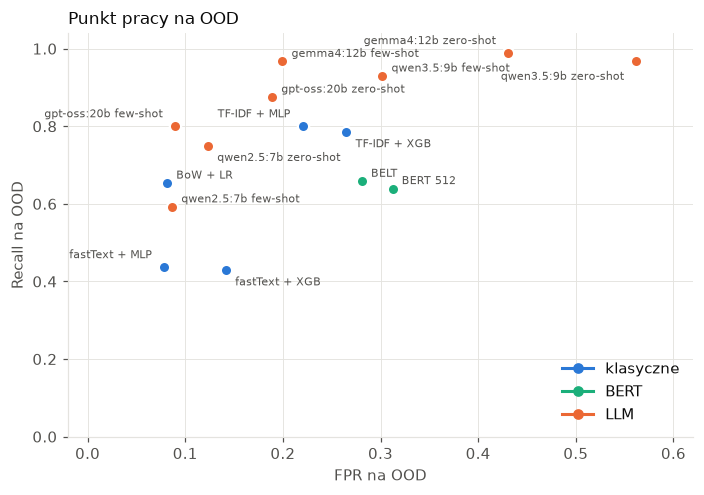

,rodzina,próg,recall,fpr,f1
model,,,,,
BoW + LR,klasyczne,0.9836,0.6533,0.0814,0.7568
TF-IDF + XGB,klasyczne,0.8126,0.7854,0.2651,0.7762
TF-IDF + MLP,klasyczne,0.8925,0.7995,0.2205,0.8005
fastText + XGB,klasyczne,0.9583,0.4292,0.1417,0.5515
fastText + MLP,klasyczne,0.9263,0.4363,0.0787,0.5790
BERT 512,BERT,0.0947,0.6392,0.3123,0.6658
BELT,BERT,0.2242,0.6580,0.2808,0.6889
qwen2.5:7b zero-shot,LLM,0.5000,0.7500,0.1234,0.8061
qwen3.5:9b zero-shot,LLM,0.5000,0.9670,0.5617,0.7824


In [6]:
ood = metrics.xs("OOD", level="korpus")
# przesunięcia etykiet (w punktach) dla punktów leżących blisko siebie
LABEL_OFFSETS = {"TF-IDF + MLP": (-8, 6), "TF-IDF + XGB": (6, -10), "fastText + MLP": (-8, 6), "fastText + XGB": (6, -10),
                 "gpt-oss:20b few-shot": (-8, 6), "qwen2.5:7b zero-shot": (6, -10), "gemma4:12b zero-shot": (-8, 6),
                 "qwen3.5:9b zero-shot": (-8, -12)}
figure, axis = plt.subplots(figsize=(6.5, 4.6))
for name, row in ood.loc[list(runs)].iterrows():
    axis.scatter(row.fpr, row.recall, color=FAMILY_COLORS[row.rodzina], s=55, edgecolors="white", linewidths=1.5, zorder=3)
    dx, dy = LABEL_OFFSETS.get(name, (6, 3))
    axis.annotate(name, (row.fpr, row.recall), xytext=(dx, dy), textcoords="offset points", fontsize=7, color=INK_SECONDARY,
                  ha="right" if dx < 0 else "left")
axis.set(xlabel="FPR na OOD", ylabel="Recall na OOD", xlim=(-0.02, 0.62), ylim=(0, 1.04))
axis.set_title("Punkt pracy na OOD", loc="left")
axis.legend(handles=handles, loc="lower right", frameon=False)
figure.tight_layout()
figure.savefig(FIGURES / "ood_operating_points.pdf", bbox_inches="tight")
plt.show()
display(ood[["rodzina", "próg", "recall", "fpr", "f1"]])